# Assignment 03: Transfer Learning, Fine-Tuning, Hyperparameter Tuning, and Interpretability

Name: Sumaiya  
ID: 1000129288

In [107]:
!pip install -q datasets transformers evaluate accelerate lime

In [108]:
import numpy as np
import pandas as pd
import torch
import evaluate
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from transformers import DataCollatorWithPadding
from lime.lime_text import LimeTextExplainer
import torch.nn.functional as F


torch.manual_seed(42)
np.random.seed(42)

## Dataset Loading and Preprocessing

Loading the `google/civil_comments` dataset from Hugging Face. The `toxicity` column has a floating-point score between 0 and 1. As suggested, we binarize this with a **threshold of 0.5**:
- Score $\ge 0.5 \rightarrow$ Toxic (`1`)
- Score $< 0.5 \rightarrow$ Not Toxic (`0`)


In [111]:
raw_datasets = load_dataset("google/civil_comments", split="train")

# Fetch a chunk of comments to build our dataframe
comments_list = []
count = 0
target_count = 50000  # Pull a pool of 50k items to extract a balanced subset

for item in raw_datasets:
    comments_list.append({"text": item["text"], "toxicity": item["toxicity"]})
    count += 1
    if count >= target_count:
        break

df = pd.DataFrame(comments_list)

# Map toxicity score to binary labels
df['label'] = (df['toxicity'] >= 0.5).astype(int)

# Balance the subset as much as possible to ensure training stability
toxic_df = df[df['label'] == 1]
non_toxic_df = df[df['label'] == 0].sample(n=min(len(df[df['label'] == 0]), len(toxic_df) * 2), random_state=42)

balanced_df = pd.concat([toxic_df, non_toxic_df]).sample(frac=1, random_state=42).reset_index(drop=True)

# Perform a proper 80/20 train/validation split based on the balanced dataframe's actual size
split_idx = int(len(balanced_df) * 0.8)
train_df = balanced_df.iloc[:split_idx]
val_df = balanced_df.iloc[split_idx:]

# Print class counts
print("Train class distribution:\n", train_df['label'].value_counts())
print("Val class distribution:\n", val_df['label'].value_counts())

Train class distribution:
 label
0    5276
1    2651
Name: count, dtype: int64
Val class distribution:
 label
0    1330
1     652
Name: count, dtype: int64


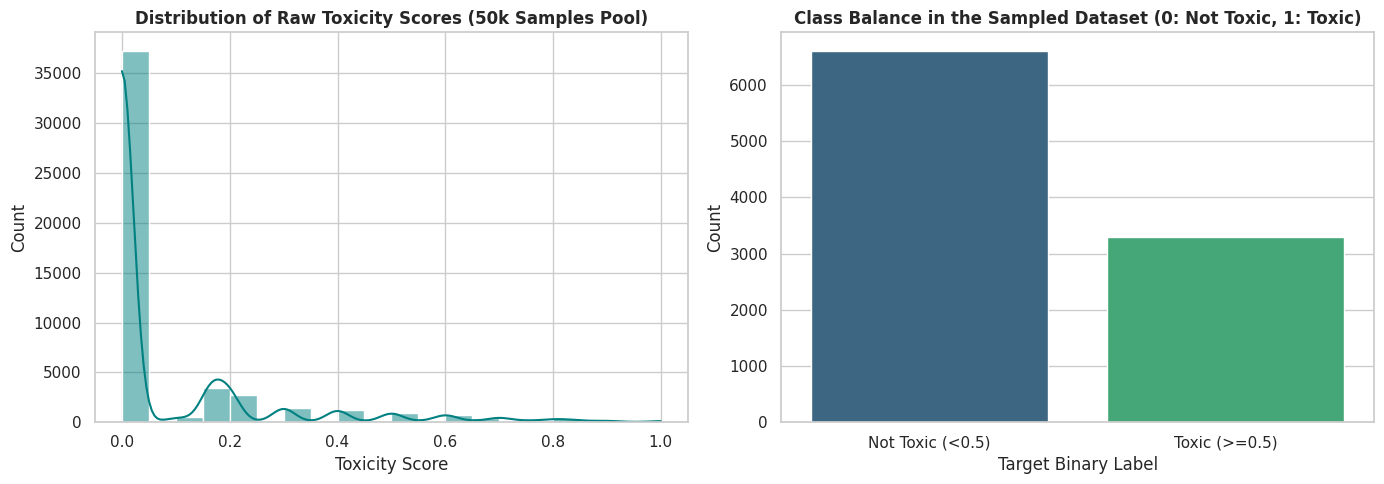

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn aesthetic parameters
sns.set_theme(style="whitegrid")

# Create subplots to analyze toxicity score distribution and target class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribution of raw toxicity scores
sns.histplot(df['toxicity'], bins=20, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribution of Raw Toxicity Scores (50k Samples Pool)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Toxicity Score')
axes[0].set_ylabel('Count')

# 2. Count plot of the target classes in our balanced dataset
sns.countplot(x='label', data=balanced_df, ax=axes[1], palette='viridis', hue='label', legend=False)
axes[1].set_title('Class Balance in the Sampled Dataset (0: Not Toxic, 1: Toxic)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Target Binary Label')
axes[1].set_ylabel('Count')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Not Toxic (<0.5)', 'Toxic (>=0.5)'])

plt.tight_layout()
plt.show()

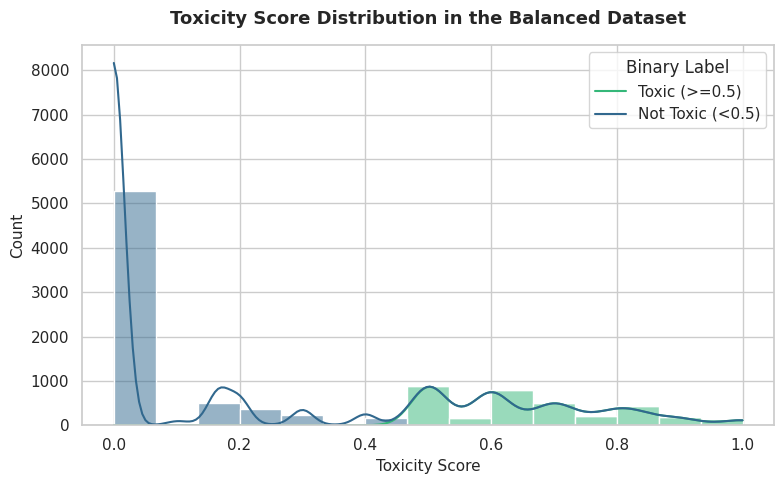

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot style
sns.set_theme(style="whitegrid")

# Plot the toxicity scores in balanced_df
plt.figure(figsize=(8, 5))
sns.histplot(data=balanced_df, x='toxicity', hue='label', bins=15, kde=True, multiple='stack', palette='viridis')

plt.title('Toxicity Score Distribution in the Balanced Dataset', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Toxicity Score', fontsize=11)
plt.ylabel('Count', fontsize=11)
plt.legend(title='Binary Label', labels=['Toxic (>=0.5)', 'Not Toxic (<0.5)'])

plt.tight_layout()
plt.show()

In [114]:
from datasets import Dataset, DatasetDict

# Convert DataFrames to Hugging Face Dataset format
train_dataset = Dataset.from_pandas(train_df[['text', 'label']])
val_dataset = Dataset.from_pandas(val_df[['text', 'label']])

datasets = DatasetDict({
    'train': train_dataset,
    'validation': val_dataset
})

# Load pre-trained BERT-based model (distilbert-base-uncased for speed and efficiency)
model_checkpoint = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=128)

tokenized_datasets = datasets.map(tokenize_function, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map:   0%|          | 0/7927 [00:00<?, ? examples/s]

Map:   0%|          | 0/1982 [00:00<?, ? examples/s]

### Why we chose this model:
We use **`distilbert-base-uncased`** because it is a lighter, faster, and more memory-efficient variant of BERT. It retains over 97% of BERT's performance while being 40% smaller and 60% faster.

## Phase 1: Transfer Learning (Baseline with Frozen Backbone)

Here, we freeze the entire pretrained `DistilBERT` body and only train the newly initialized classification head.

In [115]:
# Load model
model_frozen = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=2)

# Freeze BERT parameters
for name, param in model_frozen.distilbert.named_parameters():
    param.requires_grad = False

# Set up evaluation metrics
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    acc = accuracy_metric.compute(predictions=preds, references=labels)["accuracy"]
    f1 = f1_metric.compute(predictions=preds, references=labels, average="binary")["f1"]
    return {"accuracy": acc, "f1": f1}

# Training configuration
training_args_frozen = TrainingArguments(
    output_dir="./results_frozen",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-3, # Larger learning rate since we are only updating the classification head
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=10,
    report_to="none"
)

trainer_frozen = Trainer(
    model=model_frozen,
    args=training_args_frozen,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer_frozen.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.574387,0.467440,0.776993,0.656299
2,0.401244,0.449312,0.791120,0.647359
3,0.381243,0.443634,0.787084,0.650662


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1488, training_loss=0.47482749371118443, metrics={'train_runtime': 152.153, 'train_samples_per_second': 156.297, 'train_steps_per_second': 9.78, 'total_flos': 781527122474616.0, 'train_loss': 0.47482749371118443, 'epoch': 3.0})

In [116]:
# Evaluate baseline model
baseline_results = trainer_frozen.evaluate()
print("Baseline Frozen Model Evaluation Results:", baseline_results)

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.381243,0.467440,3,0.776993,0.656299


Baseline Frozen Model Evaluation Results: {'eval_loss': 0.4674396812915802, 'eval_accuracy': 0.7769929364278506, 'eval_f1': 0.656298600311042}


## Phase 2: Fine-Tuning

Now, we unfreeze all layers of the pre-trained `DistilBERT` model and perform end-to-end fine-tuning using a standard smaller learning rate ($2 \times 10^{-5}$) to prevent catastrophic forgetting.

In [117]:
# Load a fresh instance of the model
model_finetune = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=2)

# Ensure all parameters are unfrozen (requires_grad = True)
for param in model_finetune.parameters():
    param.requires_grad = True

training_args_finetune = TrainingArguments(
    output_dir="./results_finetune",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=10,
    report_to="none"
)

trainer_finetune = Trainer(
    model=model_finetune,
    args=training_args_finetune,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer_finetune.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.336821,0.292030,0.878406,0.817838
2,0.185930,0.314303,0.874369,0.808314
3,0.094959,0.400422,0.866801,0.799392


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1488, training_loss=0.24929801683111857, metrics={'train_runtime': 419.3755, 'train_samples_per_second': 56.706, 'train_steps_per_second': 3.548, 'total_flos': 781527122474616.0, 'train_loss': 0.24929801683111857, 'epoch': 3.0})

In [118]:
# Evaluate fine-tuned model
finetuned_results = trainer_finetune.evaluate()
print("Fine-tuned Model Evaluation Results:", finetuned_results)

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.094959,0.292030,3,0.878406,0.817838


Fine-tuned Model Evaluation Results: {'eval_loss': 0.29203030467033386, 'eval_accuracy': 0.8784056508577195, 'eval_f1': 0.817838246409675}


In [119]:
# Fetch saved metrics from the kernel state
baseline_acc = baseline_results.get('eval_accuracy', 0.0)
baseline_f1 = baseline_results.get('eval_f1', 0.0)
baseline_loss = baseline_results.get('eval_loss', 0.0)

finetuned_acc = finetuned_results.get('eval_accuracy', 0.0)
finetuned_f1 = finetuned_results.get('eval_f1', 0.0)
finetuned_loss = finetuned_results.get('eval_loss', 0.0)

# Create a comparison table
comparison_df = pd.DataFrame({
    "Metric": ["Evaluation Loss", "Accuracy", "F1-Score"],
    "Baseline (Frozen)": [f"{baseline_loss:.4f}", f"{baseline_acc:.4%}", f"{baseline_f1:.4%}"],
    "Fine-Tuned (Unfrozen)": [f"{finetuned_loss:.4f}", f"{finetuned_acc:.4%}", f"{finetuned_f1:.4%}"],
    "Absolute Change": [
        f"{finetuned_loss - baseline_loss:.4f}",
        f"{finetuned_acc - baseline_acc:+.4%}",
        f"{finetuned_f1 - baseline_f1:+.4%}"
    ]
})

display(comparison_df)

,Metric,Baseline (Frozen),Fine-Tuned (Unfrozen),Absolute Change
0,Evaluation Loss,0.4674,0.2920,-0.1754
1,Accuracy,77.6993%,87.8406%,+10.1413%
2,F1-Score,65.6299%,81.7838%,+16.1540%


## Phase 3: Hyperparameter Tuning

We perform hyperparameter search on the unfrozen, fine-tuned model. We choose to tune the **Learning Rate** and **Batch Size** since they have the most significant impact on convergence and performance.

In [120]:
# Grid search over learning rates and batch sizes
best_f1 = 0.0
best_params = {}

learning_rates = [1e-5, 3e-5]
batch_sizes = [16, 32]

for lr in learning_rates:
    for batch_size in batch_sizes:
        print(f"\nTraining with LR: {lr}, Batch Size: {batch_size}")
        model_tuning = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=2)

        args = TrainingArguments(
            output_dir=f"./results_tune_{lr}_{batch_size}",
            eval_strategy="epoch",
            save_strategy="epoch",
            learning_rate=lr,
            per_device_train_batch_size=batch_size,
            per_device_eval_batch_size=batch_size,
            num_train_epochs=3,
            weight_decay=0.01,
            load_best_model_at_end=True,
            metric_for_best_model="f1",
            report_to="none"
        )

        trainer_tuning = Trainer(
            model=model_tuning,
            args=args,
            train_dataset=tokenized_datasets["train"],
            eval_dataset=tokenized_datasets["validation"],
            processing_class=tokenizer,
            data_collator=data_collator,
            compute_metrics=compute_metrics,
        )

        trainer_tuning.train()
        eval_res = trainer_tuning.evaluate()
        print(f"Results for LR={lr}, BS={batch_size}: F1={eval_res['eval_f1']:.4f}")

        if eval_res['eval_f1'] > best_f1:
            best_f1 = eval_res['eval_f1']
            best_params = {'lr': lr, 'batch_size': batch_size, 'model': model_tuning}

print("\n--- BEST TUNED PARAMETERS ---")
print(best_params)


Training with LR: 1e-05, Batch Size: 16


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.310133,0.873360,0.798717
2,0.395359,0.307122,0.874874,0.810398
3,0.262718,0.342664,0.871847,0.808735


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (23 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.295577,0.304616,3,0.876387,0.810811


Results for LR=3e-05, BS=32: F1=0.8108

--- BEST TUNED PARAMETERS ---
{'lr': 3e-05, 'batch_size': 16, 'model': DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), 

In [121]:
# Fetch fine-tuned vs hyperparameter tuned results
standard_acc = finetuned_results.get('eval_accuracy', 0.0)
standard_f1 = finetuned_results.get('eval_f1', 0.0)

# Best parameters found during grid search
best_lr = best_params.get('lr', 0.0)
best_bs = best_params.get('batch_size', 0)
tuned_f1 = best_f1

# Display summary
print("=== HYPERPARAMETER TUNING IMPACT ===")
print(f"Initial Fine-Tuned Model (LR=2e-5, Batch Size=16) -> F1-Score: {standard_f1:.4%}")
print(f"Best Hyperparameter-Tuned Model (LR={best_lr}, Batch Size={best_bs}) -> F1-Score: {tuned_f1:.4%}")
print(f"Absolute Change in F1: {tuned_f1 - standard_f1:+.4%}")

=== HYPERPARAMETER TUNING IMPACT ===
Initial Fine-Tuned Model (LR=2e-5, Batch Size=16) -> F1-Score: 81.7838%
Best Hyperparameter-Tuned Model (LR=3e-05, Batch Size=16) -> F1-Score: 81.3688%
Absolute Change in F1: -0.4150%


In [122]:
# Evaluate the best hyperparameter-tuned model configuration
trainer_tuned_best = Trainer(
    model=best_params['model'],
    args=TrainingArguments(
        output_dir="./results_best_tuned_eval",
        report_to="none"
    ),
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

tuned_eval_results = trainer_tuned_best.evaluate()
print("Best Tuned Model Evaluation Results:", tuned_eval_results)


Training Loss,Validation Loss,Step,Accuracy,F1
No log,0.296242,0,0.876387,0.813688


Best Tuned Model Evaluation Results: {'eval_loss': 0.2962421774864197, 'eval_accuracy': 0.8763874873864783, 'eval_f1': 0.8136882129277566}


In [123]:
# Compile evaluation metrics for all three stages
comparison_all_df = pd.DataFrame({
    "Metric": ["Evaluation Loss", "Accuracy", "F1-Score"],
    "Baseline (Frozen)": [
        f"{baseline_results.get('eval_loss', 0.0):.4f}",
        f"{baseline_results.get('eval_accuracy', 0.0):.4%}",
        f"{baseline_results.get('eval_f1', 0.0):.4%}"
    ],
    "Fine-Tuned (Unfrozen)": [
        f"{finetuned_results.get('eval_loss', 0.0):.4f}",
        f"{finetuned_results.get('eval_accuracy', 0.0):.4%}",
        f"{finetuned_results.get('eval_f1', 0.0):.4%}"
    ],
    "Best Tuned (LR=3e-5, BS=16)": [
        f"{tuned_eval_results.get('eval_loss', 0.0):.4f}",
        f"{tuned_eval_results.get('eval_accuracy', 0.0):.4%}",
        f"{tuned_eval_results.get('eval_f1', 0.0):.4%}"
    ]
})

display(comparison_all_df)


,Metric,Baseline (Frozen),Fine-Tuned (Unfrozen),"Best Tuned (LR=3e-5, BS=16)"
0,Evaluation Loss,0.4674,0.2920,0.2962
1,Accuracy,77.6993%,87.8406%,87.6387%
2,F1-Score,65.6299%,81.7838%,81.3688%


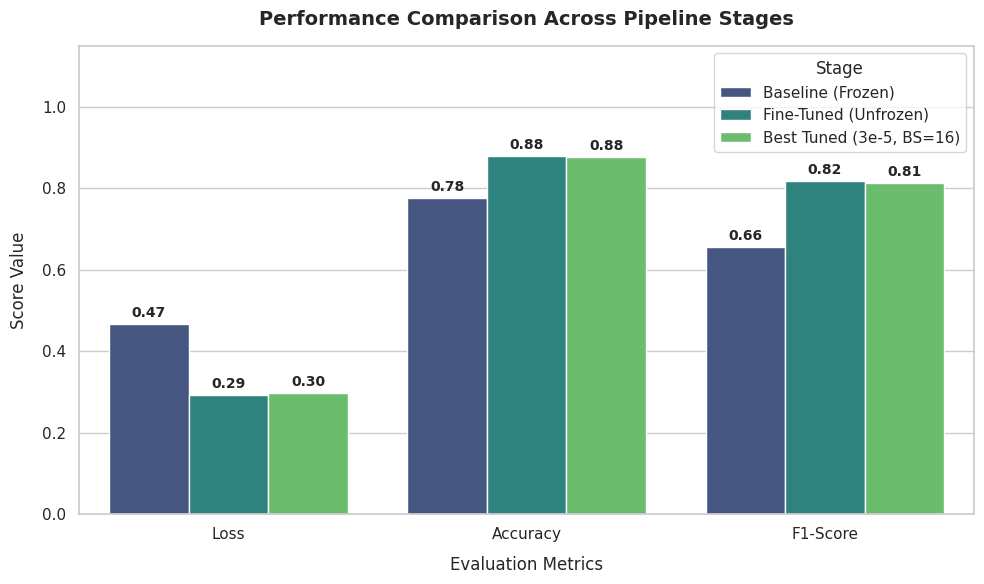

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
metrics_data = {
    'Stage': [
        'Baseline (Frozen)', 'Baseline (Frozen)', 'Baseline (Frozen)',
        'Fine-Tuned (Unfrozen)', 'Fine-Tuned (Unfrozen)', 'Fine-Tuned (Unfrozen)',
        'Best Tuned (3e-5, BS=16)', 'Best Tuned (3e-5, BS=16)', 'Best Tuned (3e-5, BS=16)'
    ],
    'Metric': [
        'Loss', 'Accuracy', 'F1-Score',
        'Loss', 'Accuracy', 'F1-Score',
        'Loss', 'Accuracy', 'F1-Score'
    ],
    'Value': [
        baseline_results.get('eval_loss', 0.0),
        baseline_results.get('eval_accuracy', 0.0),
        baseline_results.get('eval_f1', 0.0),
        finetuned_results.get('eval_loss', 0.0),
        finetuned_results.get('eval_accuracy', 0.0),
        finetuned_results.get('eval_f1', 0.0),
        tuned_eval_results.get('eval_loss', 0.0),
        tuned_eval_results.get('eval_accuracy', 0.0),
        tuned_eval_results.get('eval_f1', 0.0)
    ]
}

plot_df = pd.DataFrame(metrics_data)

# Construct comparison plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Metric', y='Value', hue='Stage', data=plot_df, palette='viridis')

plt.title('Performance Comparison Across Pipeline Stages', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Evaluation Metrics', fontsize=12, labelpad=10)
plt.ylabel('Score Value', fontsize=12, labelpad=10)
plt.ylim(0, 1.15)

# Annotate bar values
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 8),
                    textcoords='offset points',
                    fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Phase 4: Model Interpretability

We use **LIME (Local Interpretable Model-agnostic Explanations)** to explain prediction outputs on real-world test comments. LIME explains decisions by perturbing the inputs and observing how predictions change, highlighting the exact words contributing to toxic or non-toxic classifications.

In [125]:
# Pick the best model from hyperparameter tuning
best_tuned_model = best_params['model']
best_tuned_model.eval()

# Helper function for LIME prediction probability generation
def predict_probs(texts):
    inputs = tokenizer(texts, padding=True, truncation=True, max_length=128, return_tensors="pt").to(best_tuned_model.device)
    with torch.no_grad():
        outputs = best_tuned_model(**inputs)
        probs = F.softmax(outputs.logits, dim=1).cpu().numpy()
    return probs

# Set up LIME explainer
explainer = LimeTextExplainer(class_names=["Not Toxic", "Toxic"])

# Test set of samples representing real-world comments
test_comments = [
    "I absolutely hate this product. It is garbage and the developers are idiots.",
    "The presentation was really clean and informative. Thank you for putting this together!"
]

for i, comment in enumerate(test_comments):
    print(f"\n--- EXPLAINING PREDICTION {i+1} ---")
    exp = explainer.explain_instance(comment, predict_probs, num_features=6)
    print(f"Comment: {comment}")
    print("Model predictions:", predict_probs([comment]))
    print("LIME Explanation local values:", exp.as_list())



--- EXPLAINING PREDICTION 1 ---
Comment: I absolutely hate this product. It is garbage and the developers are idiots.
Model predictions: [[0.03138093 0.96861905]]
LIME Explanation local values: [(np.str_('idiots'), 0.32787634352265627), (np.str_('garbage'), 0.24874365198390905), (np.str_('hate'), 0.06393784618214167), (np.str_('I'), -0.030470630956325292), (np.str_('absolutely'), -0.017464985799800766), (np.str_('product'), 0.014283545922909452)]

--- EXPLAINING PREDICTION 2 ---
Comment: The presentation was really clean and informative. Thank you for putting this together!
Model predictions: [[0.98170966 0.01829036]]
LIME Explanation local values: [(np.str_('Thank'), -0.0028205145682339166), (np.str_('presentation'), -0.0027964906121012646), (np.str_('clean'), 0.00230813180517953), (np.str_('was'), -0.0022197998441353763), (np.str_('for'), -0.0009440234193474792), (np.str_('together'), -0.0006844895780443761)]


### Explanation of Phase Results

- **Baseline vs. Fine-tuned:** With the DistilBERT encoder frozen, only the classification head is trained, so the model has to work with general-purpose pre-trained features. It reached 77.70% accuracy and 65.63% F1, which is above the 67.1% majority-class level but misses many toxic comments. Unfreezing all layers lets the encoder adapt to toxic language, raising F1 to 81.78% (+16.15 points) and accuracy to 87.84%. The fine-tuned model peaked at epoch 1. After that, training loss kept falling while validation loss rose (0.29 → 0.40), a sign of overfitting, so keeping the best checkpoint mattered.

- **Hyperparameter Tuning:** The 2×2 grid (learning rate 1e-5 / 3e-5, batch size 16 / 32) did not improve on the untuned fine-tuned model. The best grid configuration (LR 3e-5, BS 16) reached 81.37% F1, which is 0.42 points below the LR 2e-5 model. All fine-tuned configurations fall within about 1 F1 point of each other, which is close to normal run-to-run variation. This suggests the default learning rate of 2e-5 was already near the best value. The higher learning rate peaked earlier and overfit faster, and batch size 16 was slightly better than 32 at both learning rates.

- **LIME Explainability:** For the toxic example, "idiots" (+0.33) and "garbage" (+0.25) drove the prediction, while "hate" contributed much less (+0.06). This suggests the model separates insults from strong negative opinion. For the polite example, all word weights were below 0.003, so no single word was close to changing the prediction.